# Logistics Executive Dashboard

This shipment analytics platform connects data quality, repeatable ETL and operational reporting. It helps examine delivery reliability, duration overruns and fuel efficiency across the routes and modes in the provided dataset.

## 1. Validated snapshot

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/config.yaml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display

from src.analytics import build_tables, kpis
from src.etl.extract import DataExtractor
from src.etl.transform import DataTransformer
from src.etl.validate import DataValidator
from src.utils.config_loader import ConfigLoader

raw = DataExtractor(ConfigLoader()).extract()
validation = DataValidator().validate(raw)
assert validation.report["rejected_records"] == 0, "Inspect quality report before analyzing rejected data"
df = DataTransformer().transform(validation.accepted)
tables = build_tables(df)
metrics = kpis(df)
print(f"{len(df):,} shipments | {df.dominant_mode.nunique()} observed dominant modes")

20,000 shipments | 3 observed dominant modes


The dashboard uses observed shipment data and documented metric definitions. It does not estimate savings or profitability.

## 2. Executive metrics

In [2]:
display(pd.DataFrame([metrics]).round(4))

,total_shipments,on_time_shipments,delayed_shipments,on_time_pct,avg_planned_duration_hours,avg_actual_duration_hours,avg_delay_hours_delayed,total_fuel_cost_usd,avg_fuel_cost_usd,fuel_cost_per_km,fuel_cost_per_ton_km
0,20000,10000,10000,50.0,72.0446,79.5634,17.0107,1.303777e+08,6518.8848,1.7051,0.0762


On-time rate uses all accepted shipments. Average delay uses delayed shipments only. Fuel-cost ratios use totals rather than averaging individual shipment ratios.

## 3. Build reproducible figures

In [3]:
from src.visualization import create_charts

figure_dir = ROOT / "outputs/figures"
paths = create_charts(df, tables, figure_dir)
print(f"Generated {len(paths)} figures from {len(df):,} validated shipments")

Generated 4 figures from 20,000 validated shipments


The figures are also saved as PNG files for the README and portfolio. The duration chart groups all shipments into ten-hour bins and hides bins with fewer than 20 shipments.

## 4. Delivery reliability

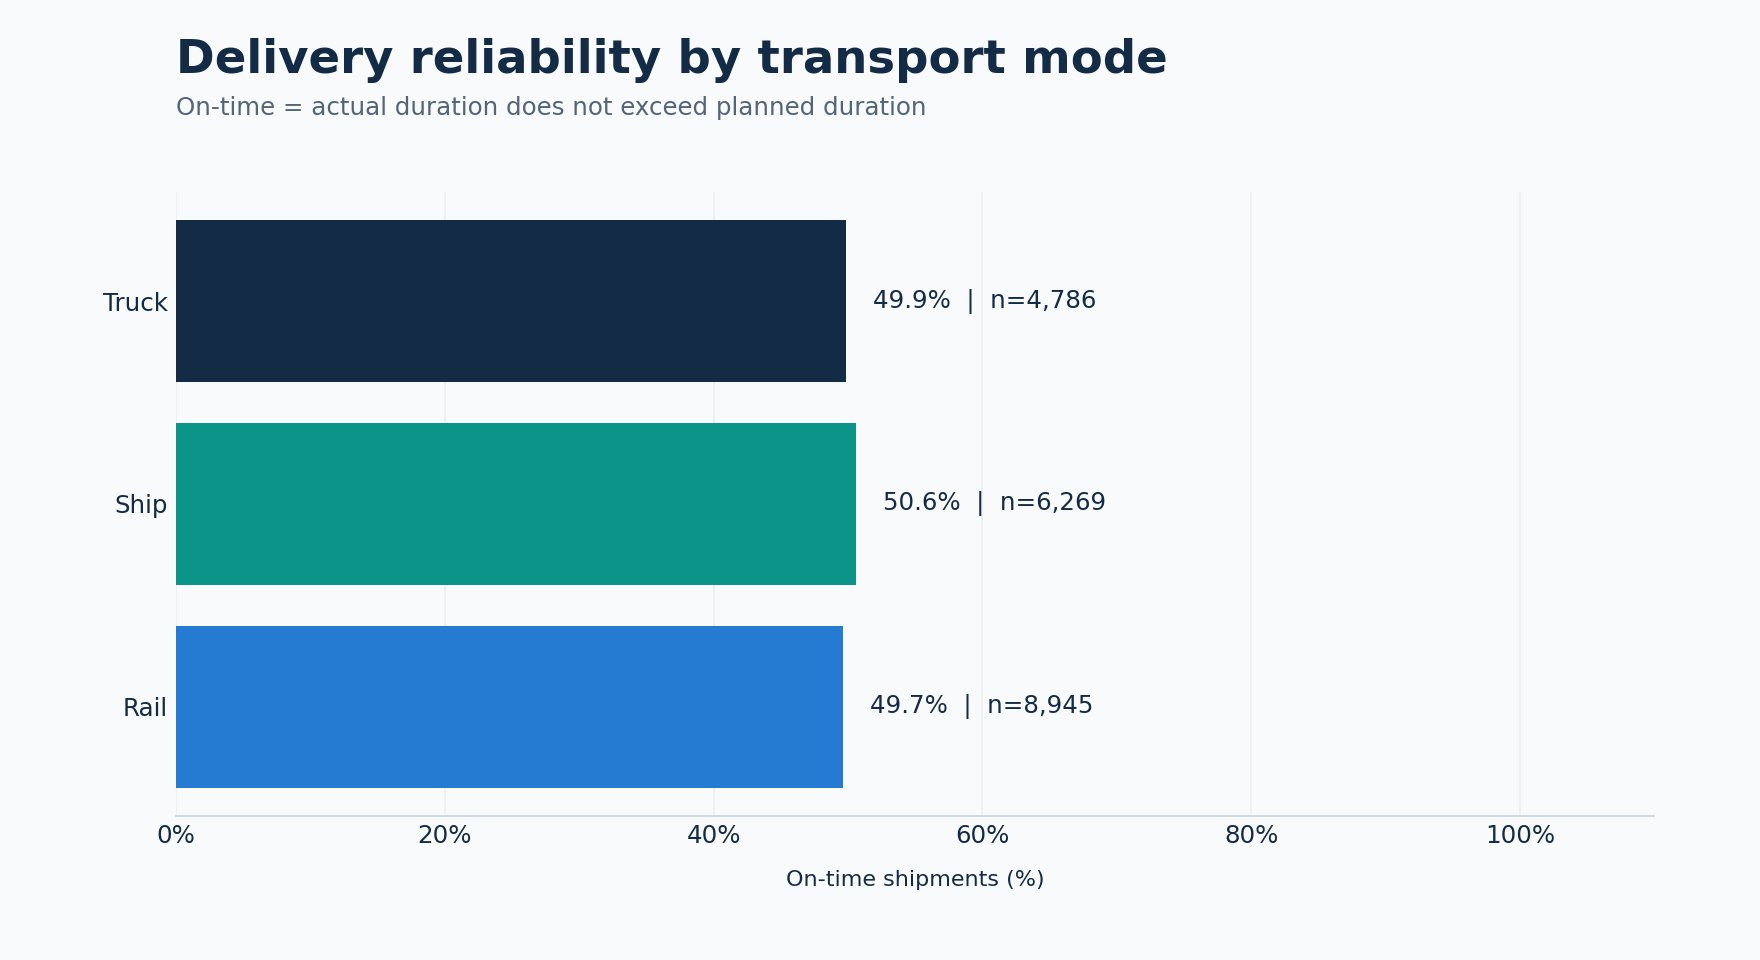

In [4]:
display(Image(filename=str(figure_dir / "01_on_time_by_mode.png")))

Compare each mode’s on-time percentage alongside its shipment count. Percentages across modes are separate rates and do not need to add to 100%.

## 5. Duration overruns

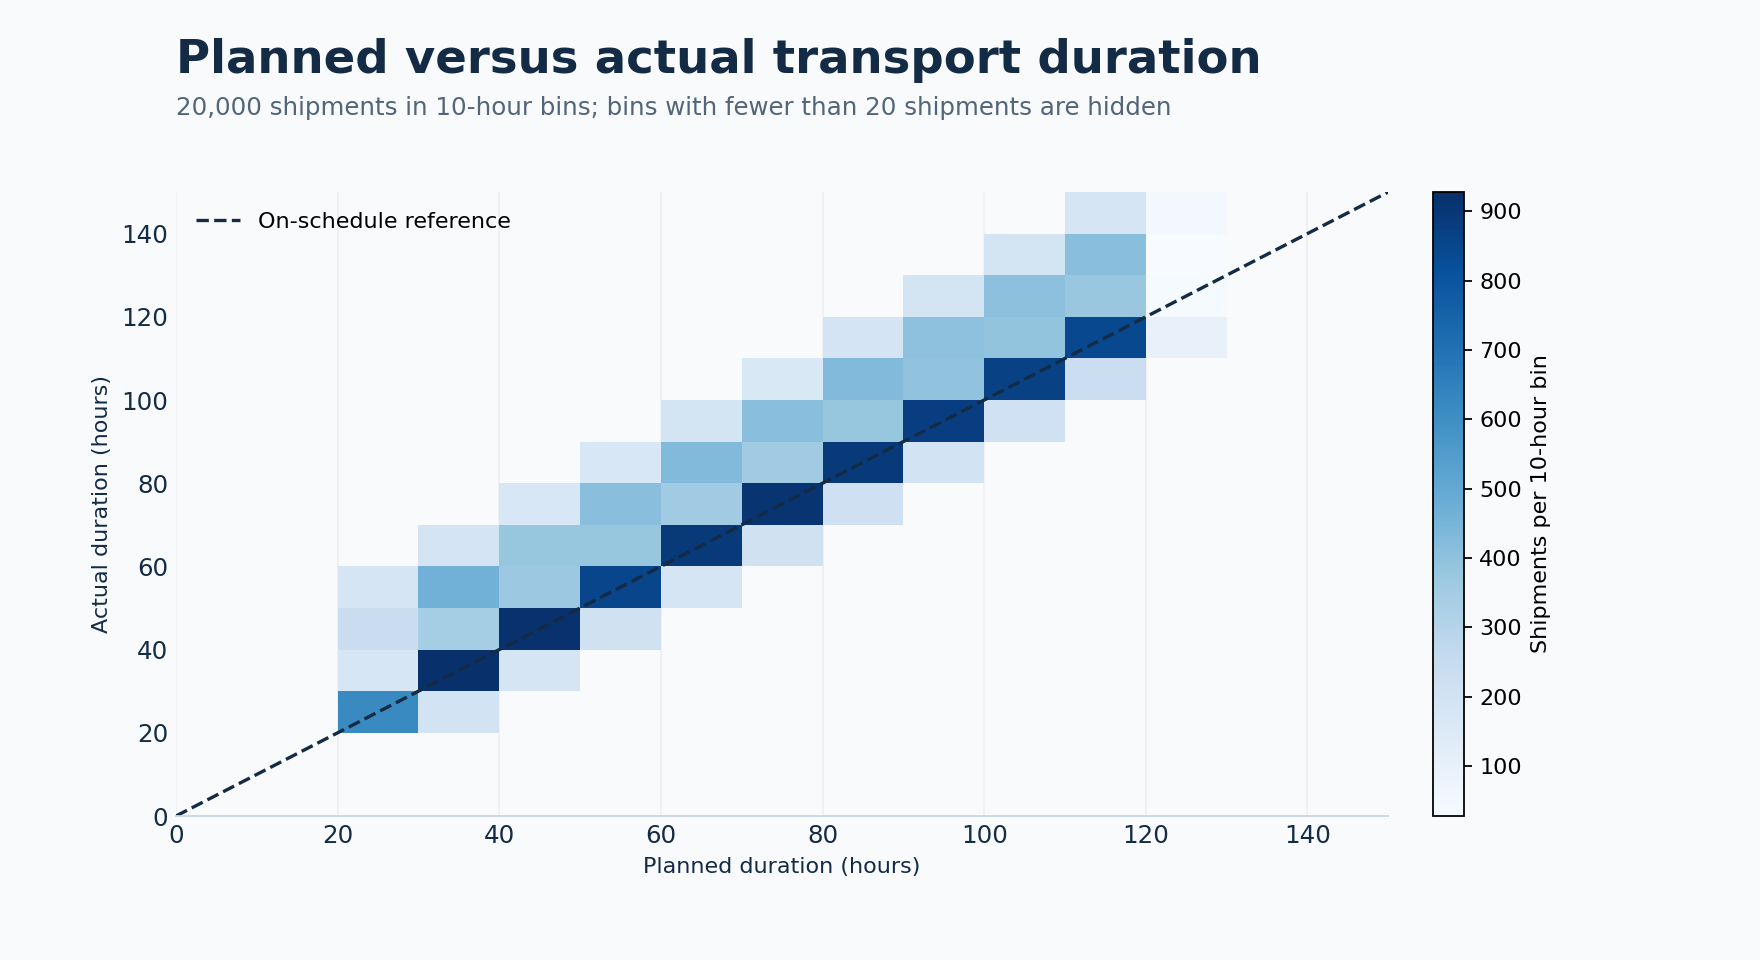

In [5]:
display(Image(filename=str(figure_dir / "02_planned_vs_actual.png")))

Bins above the dashed line represent durations longer than planned. Duration is measured in hours, not calendar days.

## 6. Fuel efficiency

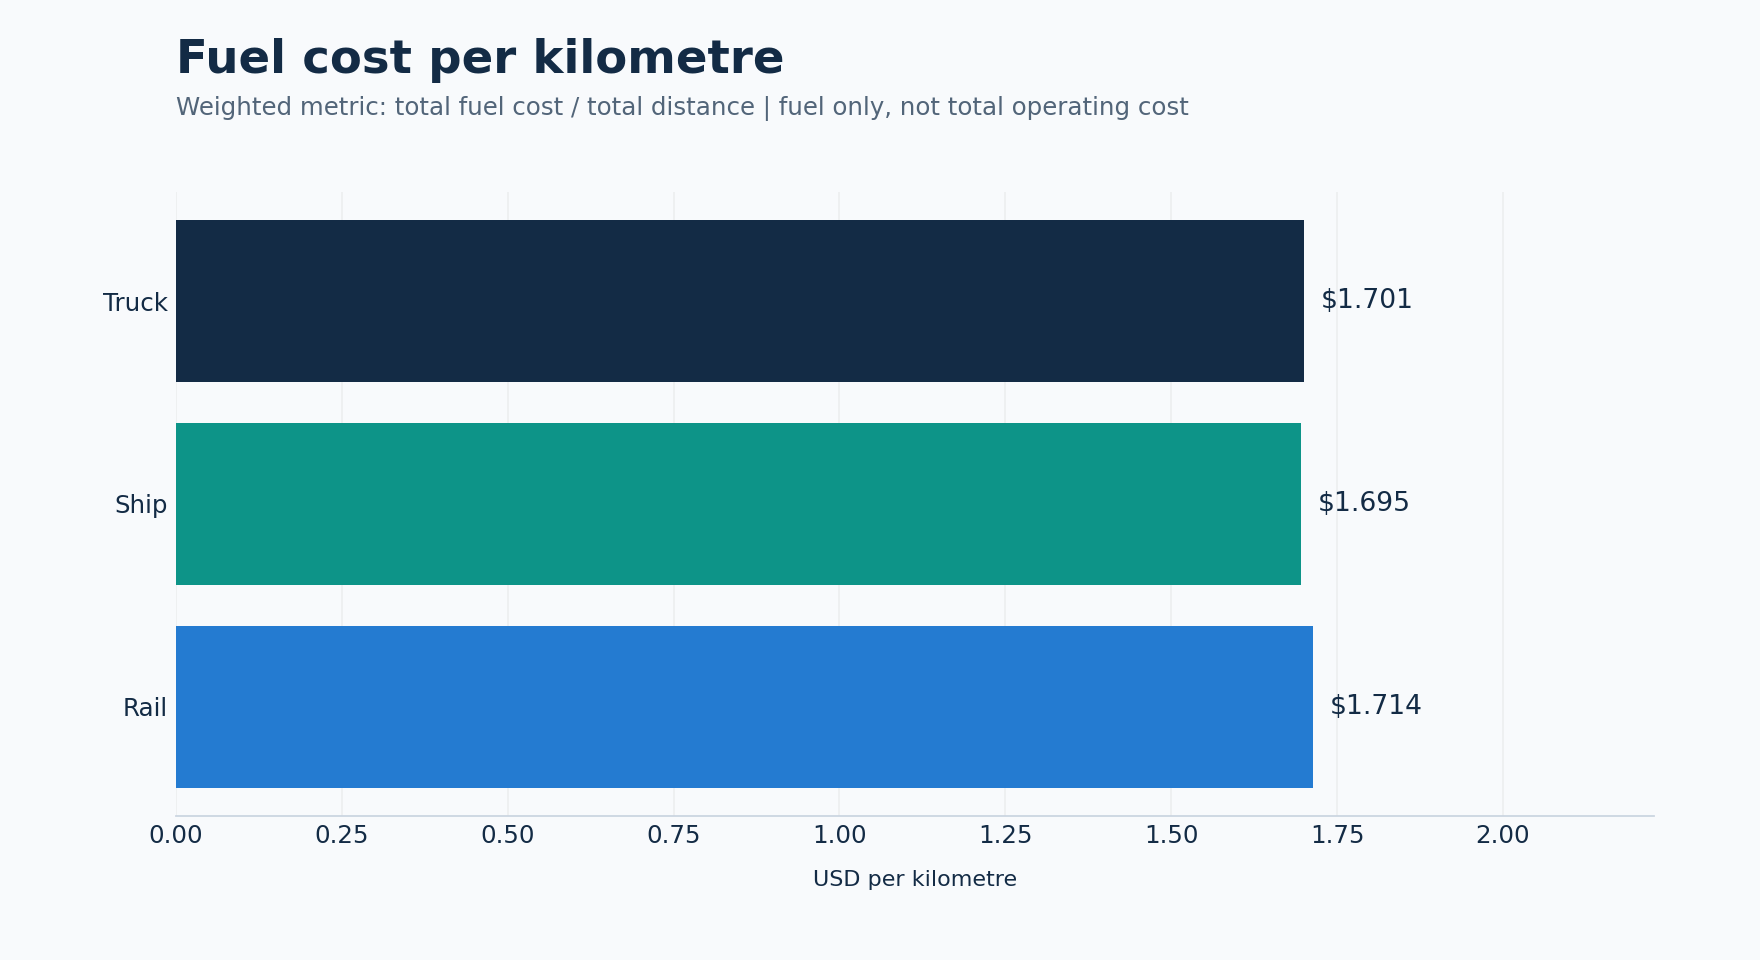

In [6]:
display(Image(filename=str(figure_dir / "03_fuel_cost_per_km.png")))

This is fuel expense per kilometre. Mode differences are descriptive and are not evidence that changing transport mode will save a particular amount.

## 7. Route priorities

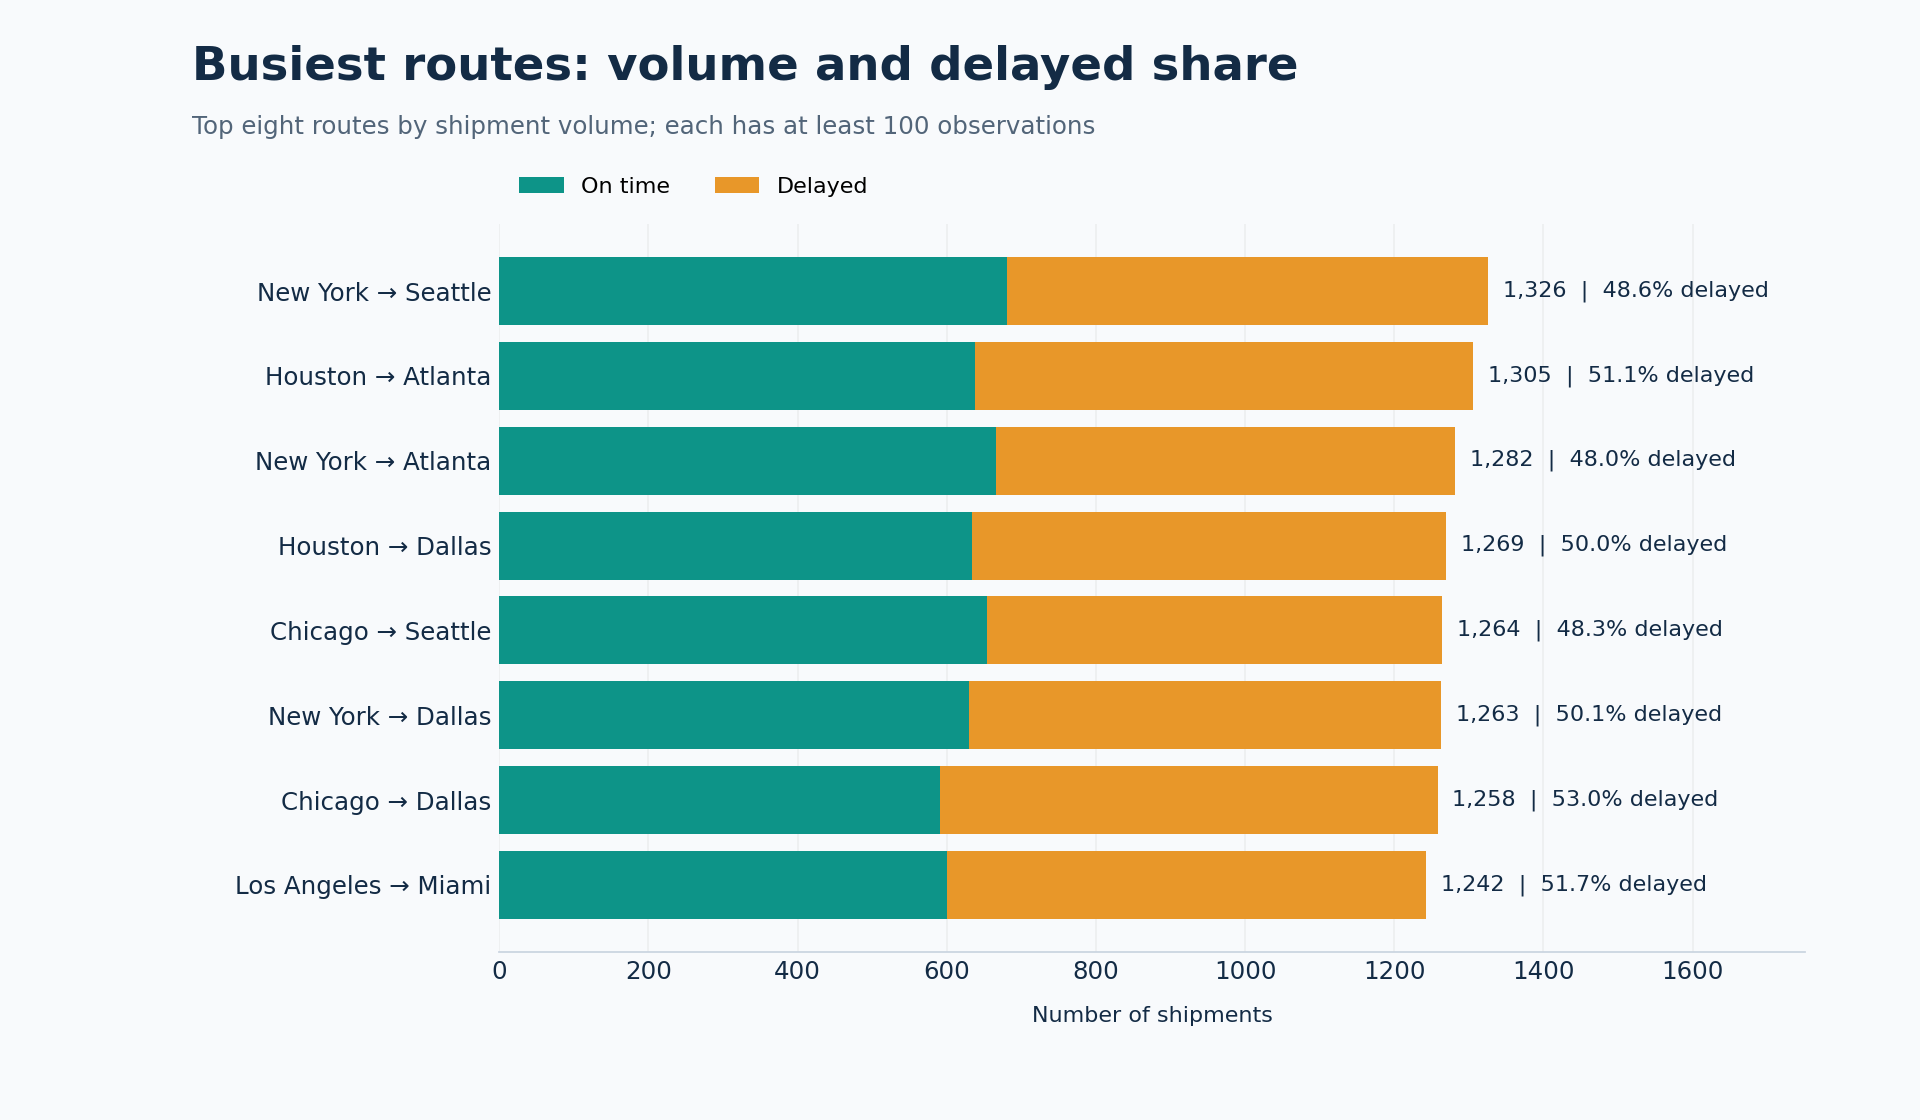

In [7]:
display(Image(filename=str(figure_dir / "04_route_volume_and_delays.png")))

Start operational review with routes that combine substantial volume and a high delayed share. Investigate shipment mix and upstream planning before proposing interventions.

## 8. Scope and limitations

The snapshot has no shipment dates, carrier identities, revenue or leg-level sequence. Monthly trends, carrier scorecards and route profitability require additional source fields. No predictive model is trained here; post-arrival measurements would need an availability review before being used in a pre-shipment forecast.